<a href="https://colab.research.google.com/github/mariya7040ai/-arabic-english-medqa-uncertainty/blob/dev/RQ3_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
from google.colab import drive
drive.mount("/content/drive")
import glob
for p in sorted(glob.glob("/content/drive/MyDrive/medqa_results/results/*.jsonl")):
    print(p)

Mounted at /content/drive
/content/drive/MyDrive/medqa_results/results/Qwen2.5-7B-Instruct_en_no_prefill_seed42_n2816.jsonl
/content/drive/MyDrive/medqa_results/results/Qwen2.5-7B-Instruct_en_seed42_n50.jsonl


In [7]:
#RESULTS_FILE = "/content/drive/MyDrive/medqa_results/results/Qwen2.5-7B-Instruct_en_no_prefill_seed42_n2816.jsonl"

In [8]:
# A. Config and loading
import json, math
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar

# RESULTS_FILE = "results/Qwen2.5-7B-Instruct_en_no_prefill_seed42_n2816.jsonl"   # EDIT
RESULTS_FILE = "/content/drive/MyDrive/medqa_results/results/Qwen2.5-7B-Instruct_en_no_prefill_seed42_n2816.jsonl"
ALPHAS = [0.05, 0.10, 0.20]     # target error levels (coverage 95%, 90%, 80%)
R = 100                         # number of random splits
SEED = 42

def load_results(path):
    with open(path, encoding="utf-8") as f:
        return pd.DataFrame([json.loads(l) for l in f])

res = load_results(RESULTS_FILE)
S = [np.asarray(s, dtype=float) for s in res["scores"]]
Y = res["answer"].values.astype(int)
n = len(Y)
Kmax = max(len(s) for s in S)
S_pad = np.full((n, Kmax), -np.inf)
for i, s in enumerate(S):
    S_pad[i, :len(s)] = s
valid = np.isfinite(S_pad)
print(n, "questions | options per question:", [int(k) for k in sorted(res["K"].unique())])

def probs_T(T, rows=None):
    Sp = S_pad if rows is None else S_pad[rows]
    Z = Sp / T
    Z = Z - np.max(Z, axis=1, keepdims=True)
    E = np.exp(Z)
    return E / E.sum(axis=1, keepdims=True)

def fit_T(idx):
    def nll(logT):
        P = probs_T(np.exp(logT), rows=idx)
        return -np.mean(np.log(P[np.arange(len(idx)), Y[idx]] + 1e-12))
    return float(np.exp(minimize_scalar(nll, bounds=(-3, 5), method="bounded").x))

2816 questions | options per question: [4]


In [9]:
# B. Split conformal prediction over repeated random splits
def conformal_q(cal_scores, alpha):
    m = len(cal_scores)
    level = min(1.0, math.ceil((m + 1) * (1 - alpha)) / m)
    return float(np.quantile(cal_scores, level, method="higher"))

def run_splits(R=R, alphas=ALPHAS, seed=SEED, fit_frac=0.25, cal_frac=0.25):
    rng = np.random.default_rng(seed); rows = []
    covered = np.zeros(n); tested = np.zeros(n)     # per-question coverage (temperature scaled, alpha = 0.10)
    for r in range(R):
        perm = rng.permutation(n)
        n_fit, n_cal = int(fit_frac * n), int(cal_frac * n)
        fit, cal, test = perm[:n_fit], perm[n_fit:n_fit + n_cal], perm[n_fit + n_cal:]
        T = fit_T(fit)
        for variant, Tv in [("raw (T=1)", 1.0), ("temperature scaled", T)]:
            P = probs_T(Tv)
            s_all = 1.0 - P[np.arange(n), Y]
            for a in alphas:
                q = conformal_q(s_all[cal], a)
                inset = valid[test] & ((1.0 - P[test]) <= q + 1e-12)
                hit = inset[np.arange(len(test)), Y[test]]
                size = inset.sum(axis=1)
                rows.append(dict(variant=variant, alpha=a, T=Tv, coverage=hit.mean(), size=size.mean(),
                                 singleton=(size == 1).mean(), empty=(size == 0).mean()))
                if variant != "raw (T=1)" and abs(a - 0.10) < 1e-9:
                    covered[test] += hit; tested[test] += 1
    return pd.DataFrame(rows), covered, tested

splits, covered, tested = run_splits()
summary = splits.groupby(["variant", "alpha"]).agg(
    target=("alpha", lambda x: 1 - x.iloc[0]),
    coverage=("coverage", "mean"), coverage_sd=("coverage", "std"),
    mean_set_size=("size", "mean"), singleton_share=("singleton", "mean"), empty_share=("empty", "mean"),
    mean_T=("T", "mean")).round(3)
print(summary)

                          target  coverage  coverage_sd  mean_set_size  \
variant            alpha                                                 
raw (T=1)          0.05     0.95     0.953        0.010          2.987   
                   0.10     0.90     0.904        0.013          2.504   
                   0.20     0.80     0.801        0.018          1.871   
temperature scaled 0.05     0.95     0.953        0.010          2.952   
                   0.10     0.90     0.903        0.013          2.500   
                   0.20     0.80     0.802        0.017          1.845   

                          singleton_share  empty_share  mean_T  
variant            alpha                                        
raw (T=1)          0.05             0.205          0.0   1.000  
                   0.10             0.305          0.0   1.000  
                   0.20             0.486          0.0   1.000  
temperature scaled 0.05             0.152          0.0   8.763  
                 

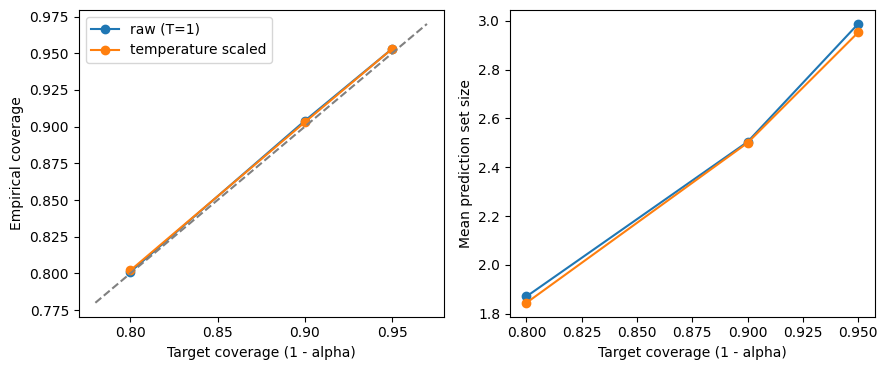

In [10]:
# C. Plot: empirical versus target coverage, and mean set size
fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
for v, g in summary.reset_index().groupby("variant"):
    ax[0].plot(g["target"], g["coverage"], "o-", label=v)
    ax[1].plot(g["target"], g["mean_set_size"], "o-", label=v)
ax[0].plot([0.78, 0.97], [0.78, 0.97], "--", color="gray")
ax[0].set_xlabel("Target coverage (1 - alpha)"); ax[0].set_ylabel("Empirical coverage"); ax[0].legend()
ax[1].set_xlabel("Target coverage (1 - alpha)"); ax[1].set_ylabel("Mean prediction set size")
plt.tight_layout(); plt.show()

In [11]:
# D. Exploratory: coverage by specialty (temperature scaled, alpha = 0.10). Marginal coverage is guaranteed; per-group coverage is not.
cov_q = covered / np.maximum(tested, 1)
tab = (res.assign(cov=cov_q).groupby("specialty")["cov"].agg(["count", "mean"])
       .rename(columns={"count": "n", "mean": "coverage"}).sort_values("n", ascending=False))
print(tab[tab["n"] >= 30].round(3))
print("target coverage: 0.90 | questions in groups with n < 30:", int(tab.loc[tab["n"] < 30, "n"].sum()))

                                n  coverage
specialty                                  
Dental                        845     0.907
Pathology                     259     0.942
Surgery                       249     0.881
Medicine                      185     0.855
Pharmacology                  179     0.917
Gynaecology & Obstetrics      154     0.883
Anatomy                       147     0.939
Pediatrics                    133     0.853
Physiology                    133     0.892
Biochemistry                  122     0.954
Social & Preventive Medicine   91     0.911
Microbiology                   74     0.812
Radiology                      57     0.877
Forensic Medicine              44     0.909
Ophthalmology                  43     0.961
ENT                            39     0.927
target coverage: 0.90 | questions in groups with n < 30: 62


## Selective prediction (RQ4)

margin (top-1 minus top-2): AURC = 0.2489
raw max probability: AURC = 0.2480


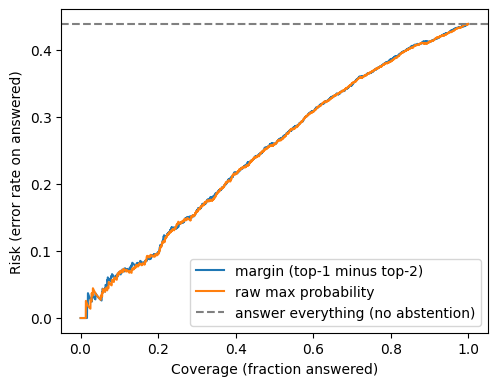

overall error rate (risk at coverage 1.0): 0.439
margin: risk at coverage 0.8 = 0.386  95% CI [0.363, 0.409]
margin: risk at coverage 0.6 = 0.308  95% CI [0.285, 0.333]
margin: risk at coverage 0.4 = 0.217  95% CI [0.189, 0.239]
margin: risk at coverage 0.2 = 0.098  95% CI [0.075, 0.131]


In [12]:
# E. Risk-coverage curves: answer only the most confident questions
Sv = np.where(valid, S_pad, -np.inf)
pred = Sv.argmax(axis=1)
correct = (pred == Y).astype(float)
srt = np.sort(Sv, axis=1)[:, ::-1]
margin = srt[:, 0] - srt[:, 1]                 # top-1 minus top-2 log-score (no fitting needed, few ties)
conf_raw = probs_T(1.0).max(axis=1)            # raw max probability (many near-ties because of saturation)

def risk_coverage(conf, correct):
    order = np.argsort(-conf, kind="stable")
    err = 1.0 - correct[order]
    k = np.arange(1, len(err) + 1)
    return k / len(err), np.cumsum(err) / k

def risk_at(conf, correct, c):
    cov, risk = risk_coverage(conf, correct)
    return float(risk[int(round(c * len(correct))) - 1])

base = 1 - correct.mean()
plt.figure(figsize=(5.5, 4.2))
for name, conf in [("margin (top-1 minus top-2)", margin), ("raw max probability", conf_raw)]:
    cov, risk = risk_coverage(conf, correct); plt.plot(cov, risk, label=name)
    print(f"{name}: AURC = {risk.mean():.4f}")
plt.axhline(base, ls="--", color="gray", label="answer everything (no abstention)")
plt.xlabel("Coverage (fraction answered)"); plt.ylabel("Risk (error rate on answered)"); plt.legend(); plt.show()
print("overall error rate (risk at coverage 1.0): %.3f" % base)
rng = np.random.default_rng(SEED)
for c in [0.8, 0.6, 0.4, 0.2]:
    vals = []
    for _ in range(500):
        idx = rng.integers(0, n, n)
        vals.append(risk_at(margin[idx], correct[idx], c))
    lo, hi = np.percentile(vals, [2.5, 97.5])
    print(f"margin: risk at coverage {c:.1f} = {risk_at(margin, correct, c):.3f}  95% CI [{lo:.3f}, {hi:.3f}]")

In [13]:
print(summary.reset_index().to_string(index=False))

           variant  alpha  target  coverage  coverage_sd  mean_set_size  singleton_share  empty_share  mean_T
         raw (T=1)   0.05    0.95     0.953        0.010          2.987            0.205          0.0   1.000
         raw (T=1)   0.10    0.90     0.904        0.013          2.504            0.305          0.0   1.000
         raw (T=1)   0.20    0.80     0.801        0.018          1.871            0.486          0.0   1.000
temperature scaled   0.05    0.95     0.953        0.010          2.952            0.152          0.0   8.763
temperature scaled   0.10    0.90     0.903        0.013          2.500            0.237          0.0   8.763
temperature scaled   0.20    0.80     0.802        0.017          1.845            0.415          0.0   8.763


In [14]:
def coverage_by_size(alpha=0.10, R=100, seed=SEED, fit_frac=0.25, cal_frac=0.25):
    rng = np.random.default_rng(seed); out = {"raw (T=1)": [], "temperature scaled": []}
    for r in range(R):
        perm = rng.permutation(n)
        n_fit, n_cal = int(fit_frac * n), int(cal_frac * n)
        fit, cal, test = perm[:n_fit], perm[n_fit:n_fit + n_cal], perm[n_fit + n_cal:]
        T = fit_T(fit)
        for variant, Tv in [("raw (T=1)", 1.0), ("temperature scaled", T)]:
            P = probs_T(Tv); s_all = 1.0 - P[np.arange(n), Y]
            q = conformal_q(s_all[cal], alpha)
            inset = valid[test] & ((1.0 - P[test]) <= q + 1e-12)
            hit = inset[np.arange(len(test)), Y[test]]
            out[variant].append(pd.DataFrame({"size": inset.sum(axis=1), "hit": hit}))
    for v, dfs in out.items():
        d = pd.concat(dfs)
        print(v); print(d.groupby("size")["hit"].agg(share=lambda x: len(x) / len(d), coverage="mean").round(3))

coverage_by_size()

raw (T=1)
      share  coverage
size                 
1     0.305     0.838
2     0.212     0.846
3     0.157     0.910
4     0.326     1.000
temperature scaled
      share  coverage
size                 
1     0.237     0.867
2     0.268     0.849
3     0.253     0.902
4     0.242     1.000
